In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/netflix_cleaned.csv")

# Handle titles with several countries ("A, B") as well as single ones
df["country"] = df["country"].str.split(",")
countries = df.explode("country")
countries["country"] = countries["country"].str.strip()
countries = countries[(countries["country"] != "") & (countries["country"] != "Unknown")]

print("Rows before:", len(df), "| rows after explode:", len(countries))
print("Unique countries:", countries["country"].nunique())
countries.head()

Rows before: 8790 | rows after explode: 8503
Unique countries: 85


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,September,125,min


In [2]:
country_counts = countries["country"].value_counts()
print(country_counts.head(15))

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Germany            104
Name: count, dtype: int64


In [3]:
top10 = country_counts.head(10)
share = (top10 / country_counts.sum() * 100).round(1)
ranking = pd.DataFrame({"Titles": top10, "Share %": share})
ranking.index.name = "Country"
ranking["Rank"] = range(1, 11)
ranking[["Rank", "Titles", "Share %"]]

,Rank,Titles,Share %
Country,,,
United States,1,3240,38.1
India,2,1057,12.4
United Kingdom,3,638,7.5
Pakistan,4,421,5.0
Canada,5,271,3.2
Japan,6,259,3.0
South Korea,7,214,2.5
France,8,213,2.5
Spain,9,182,2.1


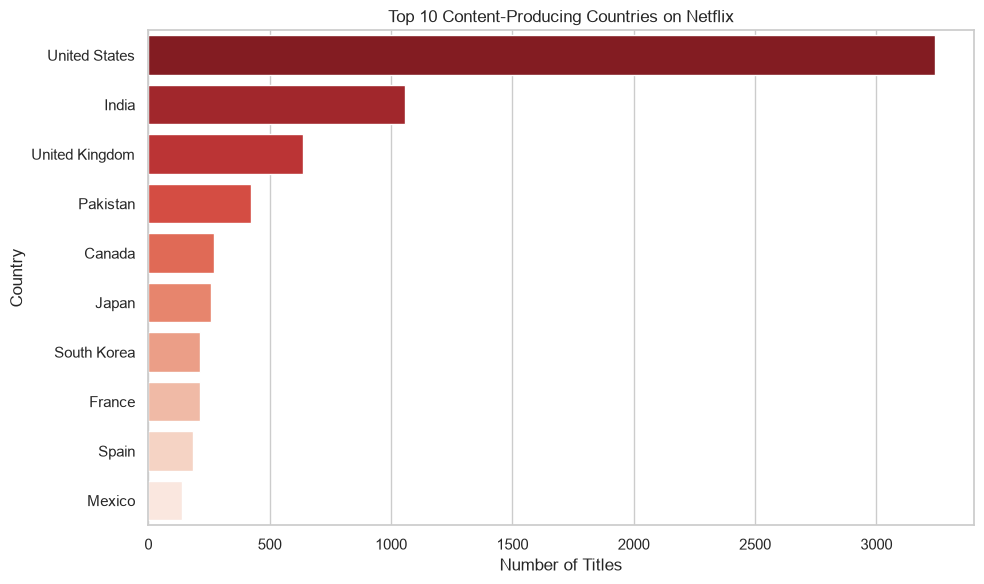

In [4]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index,
            palette="Reds_r", legend=False)
plt.title("Top 10 Content-Producing Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("top10_countries.png", dpi=150)
plt.show()

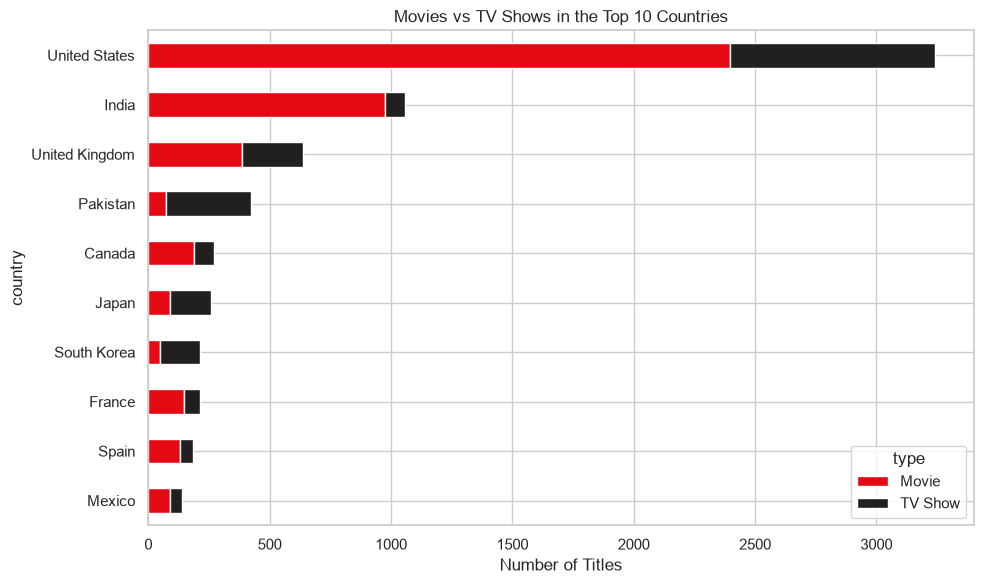

In [5]:
top_df = countries[countries["country"].isin(top10.index)]
mix = top_df.groupby(["country", "type"]).size().unstack(fill_value=0).loc[top10.index]
mix.plot(kind="barh", stacked=True, figsize=(10, 6), color=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows in the Top 10 Countries")
plt.xlabel("Number of Titles")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("top10_countries_by_type.png", dpi=150)
plt.show()

In [6]:
top_country = top10.index[0]
print(f"{top_country} leads with {top10.iloc[0]} titles ({share.iloc[0]}% of all country entries).")
print(f"The top 3 countries account for {share.head(3).sum():.1f}% of the catalog.")
print(f"The top 10 account for {share.sum():.1f}%.")

United States leads with 3240 titles (38.1% of all country entries).
The top 3 countries account for 58.0% of the catalog.
The top 10 account for 77.9%.


## Key Findings

- The United States leads with 3,240 titles (38.1% of all country entries), more than three times India, which is second with 1,057 titles.
- The top 3 countries (United States, India, United Kingdom) account for 58.0% of the catalog, so Netflix's library is concentrated in a few markets.
- The top 10 countries account for 77.9% of the catalog. After that, counts drop to around 100 to 125 per country (Egypt 123, Australia 114, Turkey 112, Nigeria 105, Germany 104).
- Asia is strongly represented, with India, Pakistan, Japan and South Korea all in the top 7.
- Insight: Netflix relies heavily on US content, but regional markets such as India, South Korea, Japan, Egypt, Turkey and Nigeria show a growing local catalog. Investing in local-language originals in these markets could attract new subscribers and reduce dependence on US titles.
